# David Silva: the creator, in numbers

Ten Premier League seasons at Manchester City (2010/11 to 2019/20), compared with every midfielder in the league over
the same decade. Official Opta season stats from the Premier League's stats API; "regular" = 1,800+ minutes in the
season (757 midfield seasons).

Charts 1 to 6 of the report: the career, the decade's assist leaders, his rank in every season, his best season as
percentiles, the rare creator-and-passer profile, and a test of how much of a dribbler he really was.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#6CABDD", "#1C2C5B", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad, 2010/11 to 2019/20"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2011 -> '2011/12'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2019/20 (official Opta stats). Season = starting year."""
    d = pd.concat([pd.read_csv(EXT / "pl_midfielders_2010-2018.csv"), pd.read_csv(EXT / "pl_midfielders_2018-2020.csv")])
    d = d.drop_duplicates(["season", "id"])
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["through"] = p90(d.throughBalls)                          # through balls per 90
    d["box"] = p90(d.totalTouchesInOppositionBox)               # touches in the opposition box per 90
    d["dribbles"] = d.successfulDribbles + d.unsuccessfulDribbles
    d["dribble_pct"] = d.successfulDribbles / d.dribbles.where(d.dribbles > 0)
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
SILVA = "David Silva"
TITLES = {2011: "Champions", 2013: "Champions", 2017: "Champions", 2018: "Champions"}

In [2]:
D = load_opta()
S = D[D.name == SILVA].sort_values("season")
R = load_opta(min_minutes=1800)
print(f"{len(R)} regular midfield seasons; Silva: {S.appearances.sum()} games, {S.goals.sum()} goals, {S.goalAssists.sum()} assists")
S[["season", "appearances", "timePlayed", "goals", "goalAssists", "keyPassesAttemptAssists", "throughBalls", "successfulDribbles", "dribbles"]]

757 regular midfield seasons; Silva: 309 games, 60 goals, 93 assists


,season,appearances,timePlayed,goals,goalAssists,keyPassesAttemptAssists,throughBalls,successfulDribbles,dribbles
117,2010,35,2563,4,7,66,30,35,53
303,2011,36,2817,6,15,89,77,38,72
489,2012,32,2521,4,8,97,46,31,51
677,2013,27,2173,7,9,77,33,29,44
874,2014,32,2659,12,7,86,39,51,69
1061,2015,24,1800,2,11,56,11,31,48
1269,2016,34,2766,4,7,75,26,46,69
1464,2017,29,2435,9,11,50,18,38,49
109,2018,33,2409,6,8,65,18,31,46
278,2019,27,1832,6,10,39,12,33,44


In [3]:
# The decade's leaders, every Premier League midfielder 2010/11 to 2019/20
DEC = D.groupby("name").agg(assists=("goalAssists", "sum"), chances=("keyPassesAttemptAssists", "sum"),
                            through=("throughBalls", "sum"), minutes=("timePlayed", "sum"))
for c in ["assists", "chances", "through"]:
    print(c, DEC[c].sort_values(ascending=False).head(4).to_dict())

assists {'David Silva': 93, 'Kevin De Bruyne': 65, 'Christian Eriksen': 62, 'Mesut Özil': 54}
chances {'David Silva': 700, 'Christian Eriksen': 509, 'Mesut Özil': 504, 'Juan Mata': 460}
through {'David Silva': 310, 'Cesc Fàbregas': 222, 'Yaya Touré': 173, 'Aaron Ramsey': 149}


In [4]:
# Rank in each season among regular midfielders (1 = best)
RANKS = {"creating": "Chances created", "through": "Through balls", "passing": "Passes in the opposition half",
         "assisting": "Assists", "box": "Touches in the opposition box", "carrying": "Successful dribbles"}
for c in RANKS:
    R["r_" + c] = R.groupby("season")[c].rank(ascending=False, method="min")
R["n"] = R.groupby("season").id.transform("size")
RS = R[R.name == SILVA].set_index("season")
RS[["n"] + ["r_" + c for c in RANKS]]

,n,r_creating,r_through,r_passing,r_assisting,r_box,r_carrying
season,,,,,,,
2010,82,8.0,10.0,10.0,13.0,5.0,23.0
2011,79,2.0,2.0,4.0,1.0,1.0,21.0
2012,71,1.0,2.0,5.0,5.0,4.0,20.0
2013,76,1.0,2.0,1.0,3.0,2.0,29.0
2014,81,2.0,1.0,4.0,14.0,3.0,21.0
2015,79,5.0,11.0,3.0,2.0,18.0,29.0
2016,74,5.0,3.0,3.0,14.0,4.0,22.0
2017,75,9.0,6.0,1.0,3.0,1.0,25.0
2018,72,3.0,6.0,2.0,3.0,1.0,23.0


In [5]:
# The rare profile: top 5 in the league in one season for BOTH chances created and passes in the opposition half (per 90)
R["top5_both"] = (R.r_creating <= 5) & (R.r_passing <= 5)
BOTH = R[R.top5_both]
print(len(BOTH), "of", len(R), "regular midfield seasons")
BOTH.groupby("name").size().sort_values(ascending=False)

17 of 757 regular midfield seasons


name
David Silva        7
Mesut Özil         5
Cesc Fàbregas      2
Samir Nasri        2
Kevin De Bruyne    1
dtype: int64

In [6]:
# Dribbling: volume and success, midfielders with 1,800+ minutes and 40+ attempted dribbles
DR = R[R.dribbles >= 40].copy()
DR["r_pct"] = DR.groupby("season").dribble_pct.rank(ascending=False, method="min")
DR["n_pct"] = DR.groupby("season").id.transform("size")
print("Silva, successful dribbles per 90 rank by season:", RS.r_carrying.astype(int).tolist(), "of", RS.n.tolist())
DR[DR.name == SILVA][["season", "dribbles", "dribble_pct", "r_pct", "n_pct"]].round(2)

Silva, successful dribbles per 90 rank by season: [23, 21, 20, 29, 21, 29, 22, 25, 23, 13] of [82, 79, 71, 76, 81, 79, 74, 75, 72, 68]


,season,dribbles,dribble_pct,r_pct,n_pct
117,2010,53,0.66,5.0,39
303,2011,72,0.53,16.0,35
489,2012,51,0.61,6.0,37
677,2013,44,0.66,9.0,39
874,2014,69,0.74,8.0,44
1061,2015,48,0.65,12.0,50
1269,2016,69,0.67,13.0,42
1464,2017,49,0.78,6.0,36
109,2018,46,0.67,6.0,34
278,2019,44,0.75,6.0,34


## Charts

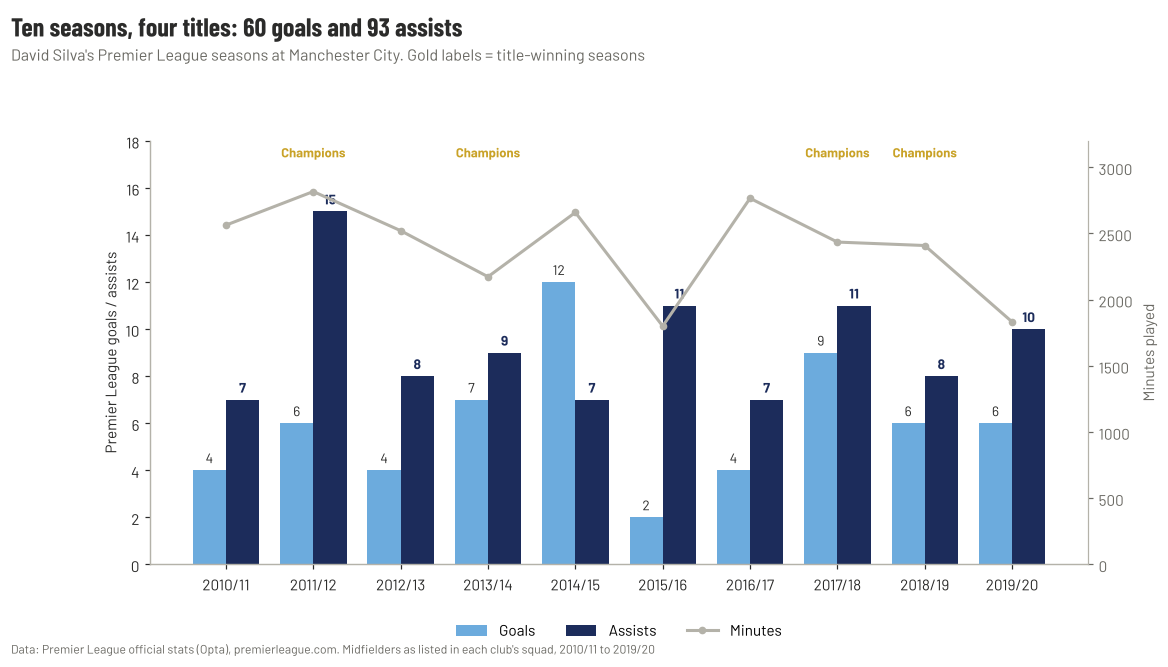

In [7]:
# Figure 1: ten seasons
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(S)); w = 0.38
ax.bar(x - w / 2, S.goals, w, color=SKY, label="Goals")
ax.bar(x + w / 2, S.goalAssists, w, color=NAVY, label="Assists")
for xi, r in zip(x, S.itertuples()):
    ax.text(xi - w / 2, r.goals + 0.3, r.goals, ha="center", fontsize=9, color=DARK)
    ax.text(xi + w / 2, r.goalAssists + 0.3, r.goalAssists, ha="center", fontsize=9, color=NAVY, fontweight="bold")
    if r.season in TITLES:
        ax.text(xi, 17.3, "Champions", ha="center", fontsize=8.5, color=GOLD, fontweight="bold")
ax2 = ax.twinx(); ax2.plot(x, S.timePlayed, color=GREY, lw=2, marker="o", ms=4, label="Minutes"); ax2.set_ylim(0, 3200)
ax2.set_ylabel("Minutes played", color=MUTED); ax2.spines["right"].set_visible(True); ax2.tick_params(colors=MUTED)
ax.set_xticks(x, [season_label(s) for s in S.season]); ax.set_ylim(0, 18); ax.set_ylabel("Premier League goals / assists")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
titles(fig, "Ten seasons, four titles: 60 goals and 93 assists",
       "David Silva's Premier League seasons at Manchester City. Gold labels = title-winning seasons", SRC_PL)
fig.savefig(FIGS / "01_career_by_season.png")

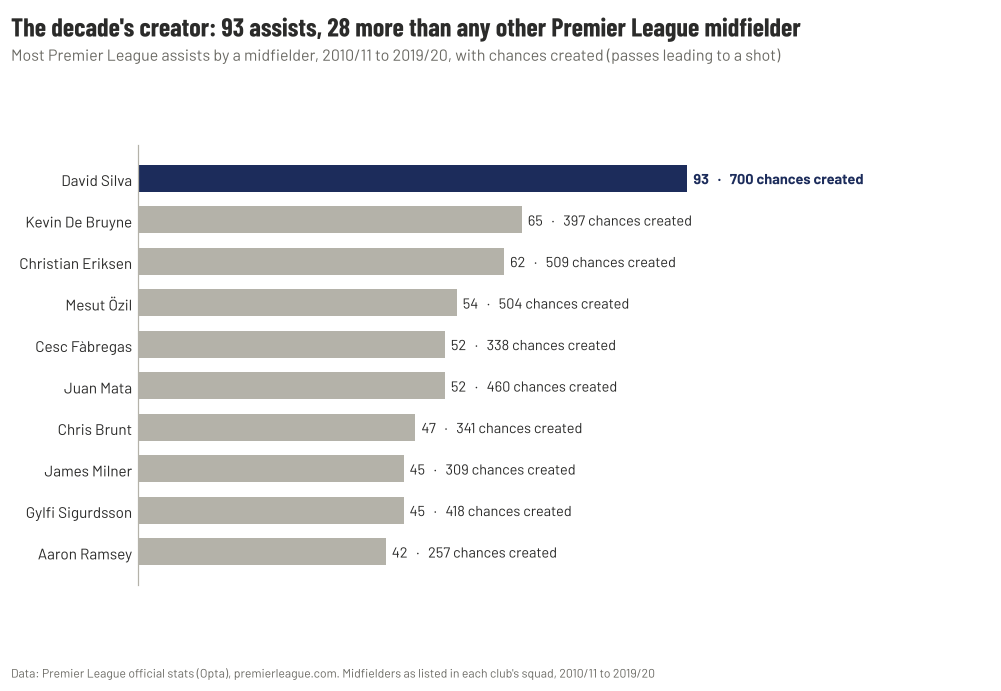

In [8]:
# Figure 2: the decade's assist leaders
top = DEC.sort_values("assists", ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(range(len(top)), top.assists, color=[NAVY if n == SILVA else GREY for n in top.index], height=0.65)
for i, (n, r) in enumerate(top.iterrows()):
    ax.text(r.assists + 1, i, f"{r.assists}   ·   {r.chances} chances created", va="center", fontsize=9.5,
            color=NAVY if n == SILVA else DARK, fontweight="bold" if n == SILVA else "normal")
ax.set_yticks(range(len(top)), top.index, fontsize=10); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", length=0); ax.set_xlim(0, top.assists.max() * 1.55)
gap = int(top.assists.iloc[-1] - top.assists.iloc[-2])
titles(fig, f"The decade's creator: 93 assists, {gap} more than any other Premier League midfielder",
       "Most Premier League assists by a midfielder, 2010/11 to 2019/20, with chances created (passes leading to a shot)", SRC_PL)
fig.savefig(FIGS / "02_decade_assists.png")

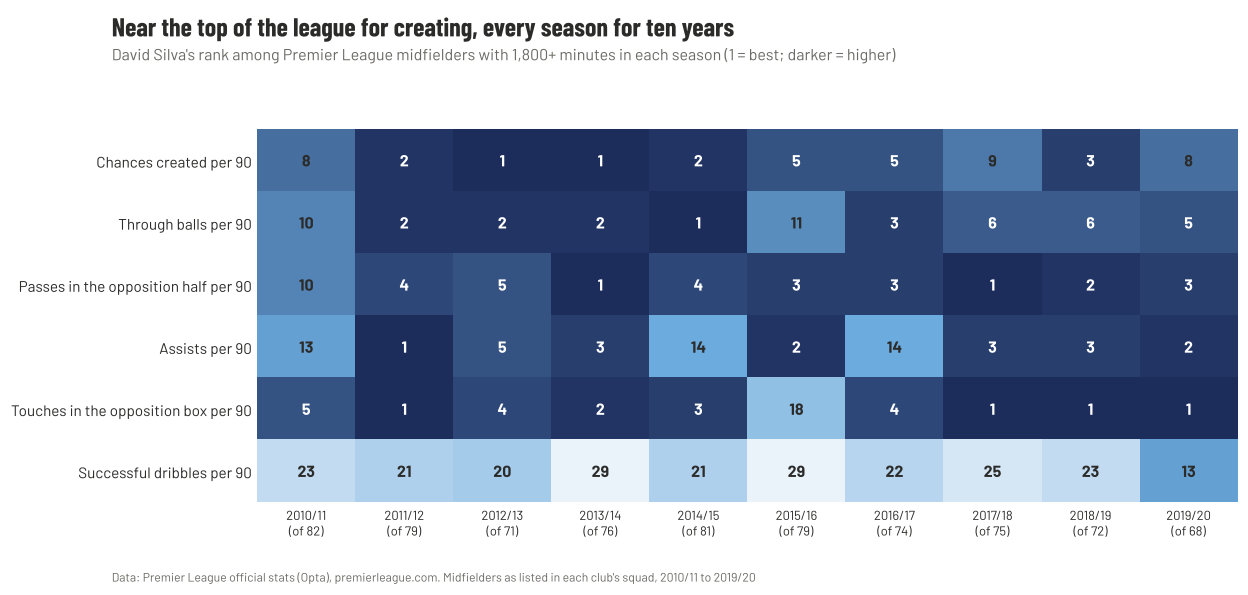

In [9]:
# Figure 3: rank in every season
M = RS[["r_" + c for c in RANKS]].T
fig, ax = plt.subplots(figsize=(11.5, 4.4))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("rk", [NAVY, SKY, "#E8F1FA", "#FFFFFF"])
ax.imshow(np.clip(M.values, 1, 40), cmap=cmap, vmin=1, vmax=40, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = int(M.values[i, j]); ax.text(j, i, v, ha="center", va="center", fontsize=10.5, fontweight="bold", color="white" if v <= 6 else DARK)
ax.set_yticks(range(len(RANKS)), [RANKS[c[2:]] + " per 90" for c in M.index], fontsize=10)
ax.set_xticks(range(M.shape[1]), [f"{season_label(s)}\n(of {int(n)})" for s, n in zip(RS.index, RS.n)], fontsize=8.5)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
titles(fig, "Near the top of the league for creating, every season for ten years",
       "David Silva's rank among Premier League midfielders with 1,800+ minutes in each season (1 = best; darker = higher)", SRC_PL)
fig.savefig(FIGS / "03_rank_every_season.png")

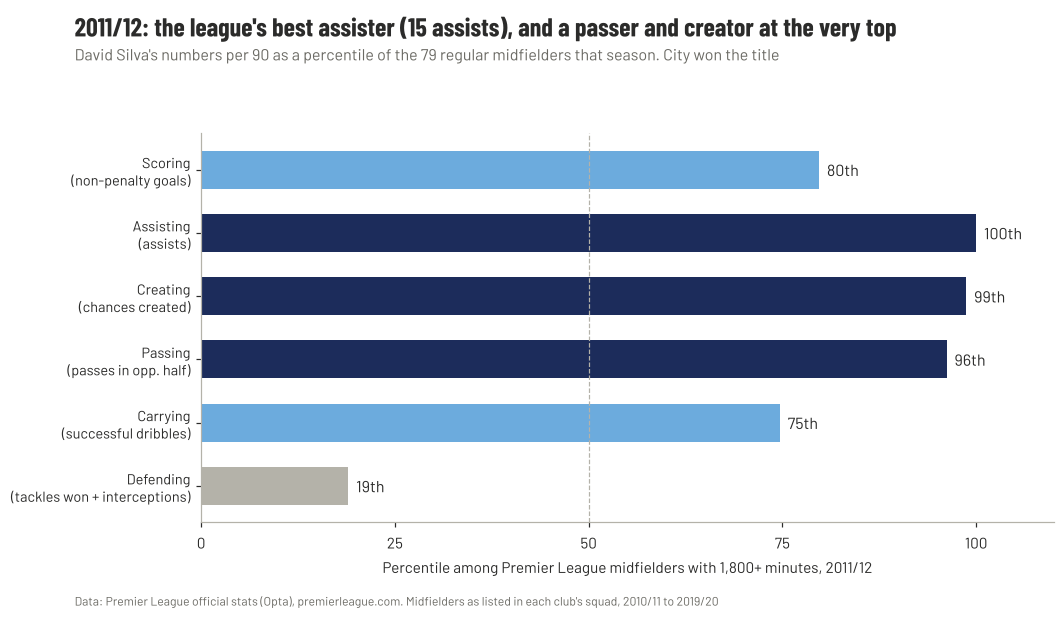

In [10]:
# Figure 4: the 2011/12 profile
best = R[R.season == 2011].copy()
for c in DIMS:
    best["p_" + c] = best[c].rank(pct=True) * 100
row = best[best.name == SILVA].iloc[0]
fig, ax = plt.subplots(figsize=(10, 4.6))
vals = [row["p_" + c] for c in DIMS]
ax.barh(range(len(DIMS)), vals, color=[NAVY if v >= 90 else SKY if v >= 60 else GREY for v in vals], height=0.6)
for i, v in enumerate(vals):
    ax.text(v + 1, i, f"{v:.0f}th", va="center", fontsize=10.5, color=DARK)
ax.set_yticks(range(len(DIMS)), [DIM_LABELS[c] for c in DIMS], fontsize=9.5); ax.invert_yaxis()
ax.set_xlim(0, 110); ax.set_xticks([0, 25, 50, 75, 100]); ax.axvline(50, color=GREY, lw=0.8, ls="--")
ax.set_xlabel("Percentile among Premier League midfielders with 1,800+ minutes, 2011/12")
titles(fig, f"2011/12: the league's best assister ({int(row.goalAssists)} assists), and a passer and creator at the very top",
       f"David Silva's numbers per 90 as a percentile of the {len(best)} regular midfielders that season. City won the title", SRC_PL)
fig.savefig(FIGS / "04_profile_2011_12.png")

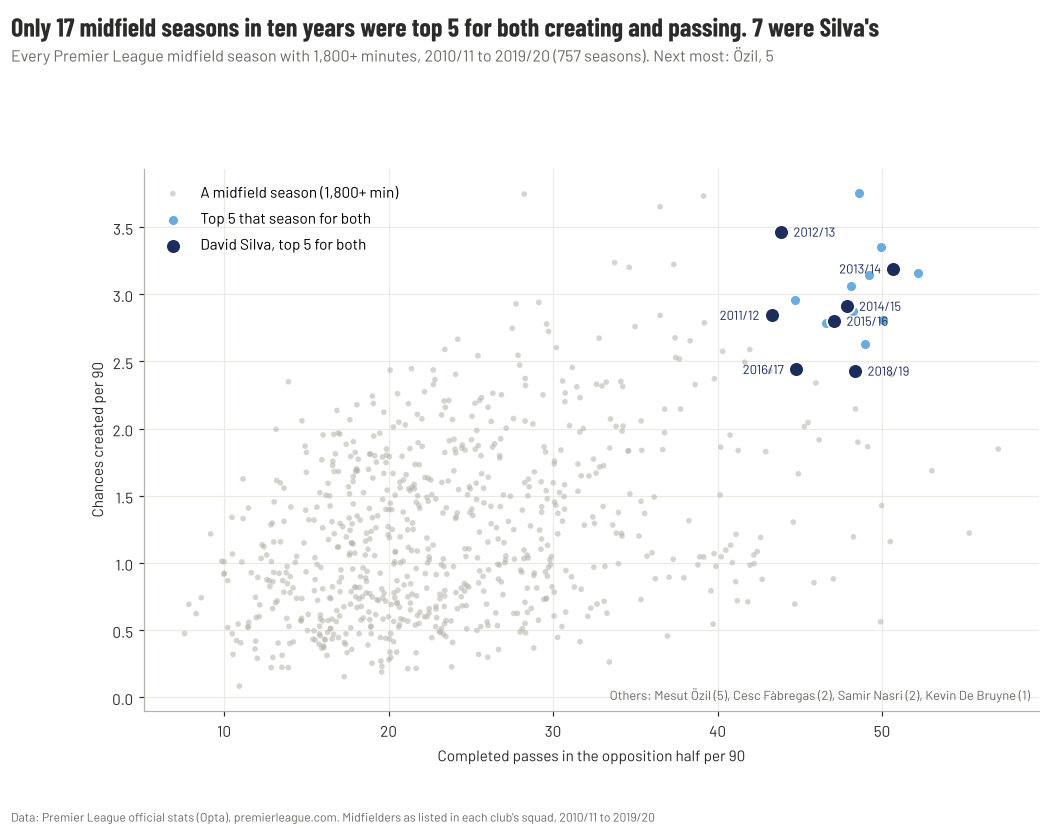

In [11]:
# Figure 5: creator and passer at once
fig, ax = plt.subplots(figsize=(10.5, 6.4))
ax.scatter(R.passing, R.creating, s=14, color=GREY, alpha=0.55, edgecolors="none", label="A midfield season (1,800+ min)")
o = BOTH[BOTH.name != SILVA]
ax.scatter(o.passing, o.creating, s=46, color=SKY, edgecolors="white", lw=0.8, zorder=3, label="Top 5 that season for both")
s = BOTH[BOTH.name == SILVA]
ax.scatter(s.passing, s.creating, s=95, color=NAVY, edgecolors="white", lw=1.2, zorder=4, label="David Silva, top 5 for both")
for k, r in enumerate(s.sort_values("creating").itertuples()):
    ax.annotate(season_label(r.season), (r.passing, r.creating), xytext=(-8 if k % 2 else 8, -3), ha="right" if k % 2 else "left", textcoords="offset points", fontsize=8.5, color=NAVY)
ax.annotate(f"Others: {', '.join(f'{n} ({k})' for n, k in o.name.value_counts().items())}", xy=(0.99, 0.02), xycoords="axes fraction", ha="right", fontsize=8.5, color=MUTED)
ax.set_xlabel("Completed passes in the opposition half per 90"); ax.set_ylabel("Chances created per 90")
ax.grid(color="#ECEAE4", lw=0.8); ax.set_axisbelow(True); ax.legend(frameon=False, loc="upper left")
n_s = len(s)
titles(fig, f"Only {len(BOTH)} midfield seasons in ten years were top 5 for both creating and passing. {n_s} were Silva's",
       f"Every Premier League midfield season with 1,800+ minutes, 2010/11 to 2019/20 ({len(R)} seasons). Next most: Özil, {int((o.name == 'Mesut Özil').sum())}", SRC_PL)
fig.savefig(FIGS / "05_creator_and_passer.png")

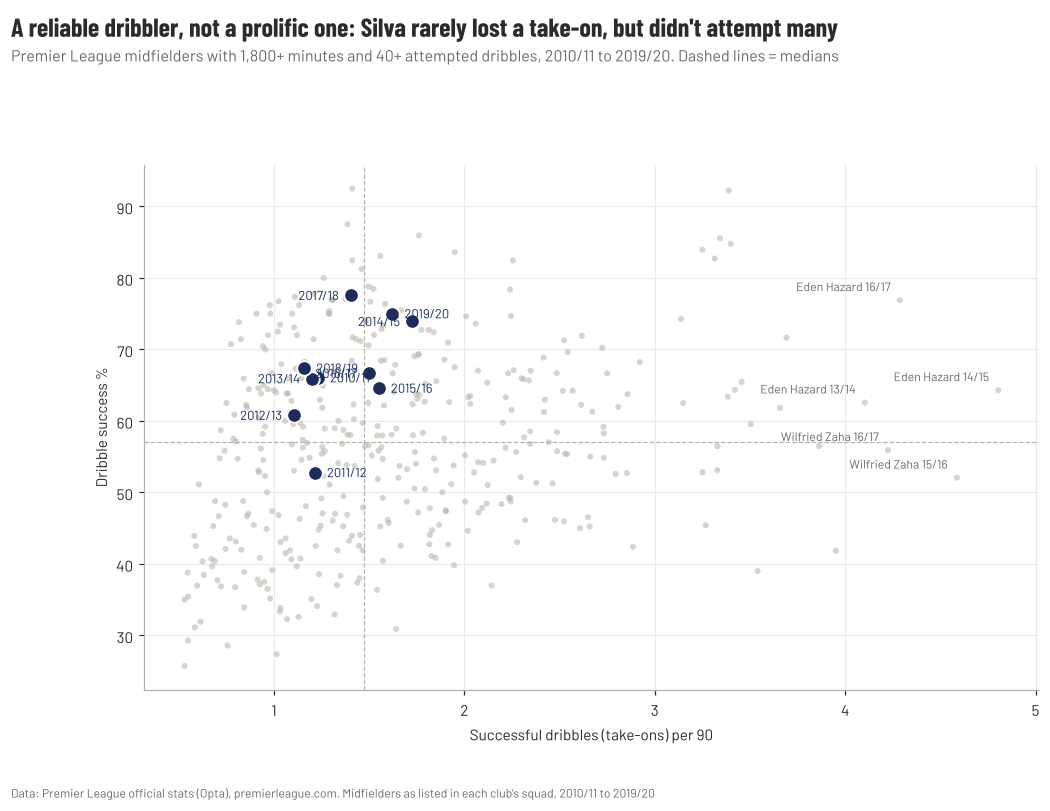

In [12]:
# Figure 6: the dribbling test
fig, ax = plt.subplots(figsize=(10.5, 6.2))
ax.scatter(DR.carrying, DR.dribble_pct * 100, s=16, color=GREY, alpha=0.55, edgecolors="none")
s = DR[DR.name == SILVA]
ax.scatter(s.carrying, s.dribble_pct * 100, s=90, color=NAVY, edgecolors="white", lw=1.2, zorder=3)
for k, r in enumerate(s.sort_values("dribble_pct").itertuples()):
    ax.annotate(season_label(r.season), (r.carrying, r.dribble_pct * 100), xytext=(-8 if k % 2 else 8, -3), ha="right" if k % 2 else "left", textcoords="offset points", fontsize=8.5, color=NAVY)
for r in DR.sort_values("carrying", ascending=False).head(5).itertuples():
    ax.annotate(f"{r.name} {season_label(r.season)[2:]}", (r.carrying, r.dribble_pct * 100), xytext=(-6, 6), textcoords="offset points", ha="right", fontsize=8, color=MUTED)
ax.axvline(DR.carrying.median(), color=GREY, lw=0.8, ls="--"); ax.axhline(DR.dribble_pct.median() * 100, color=GREY, lw=0.8, ls="--")
ax.set_xlabel("Successful dribbles (take-ons) per 90"); ax.set_ylabel("Dribble success %")
ax.grid(color="#ECEAE4", lw=0.8); ax.set_axisbelow(True)
titles(fig, "A reliable dribbler, not a prolific one: Silva rarely lost a take-on, but didn't attempt many",
       "Premier League midfielders with 1,800+ minutes and 40+ attempted dribbles, 2010/11 to 2019/20. Dashed lines = medians", SRC_PL)
fig.savefig(FIGS / "06_dribbling.png")